In [1]:
import itertools
import math
import csv
import numpy as np
import matplotlib.pyplot as plt

 MDP PARAMETERS


In [2]:
GAMMA = 0.90
THETA = 1e-6
MAX_ITERATIONS = 1000

EPISODES = 200
MAX_STEPS = 50
CAP = 2

In [3]:
STATES = list(itertools.product(range(3), repeat=6))
INDEX = {s: i for i, s in enumerate(STATES)}

INITIAL_STATE = (1, 1, 2, 2, 2, 2)
TERMINAL_STATE = (2, 2, 0, 0, 0, 0)

In [4]:
ACTION_NAME = {
    0: "Wait",
    1: "Admit Critical",
    2: "Admit Non-Critical"
}

VALID ACTIONS


In [5]:
def valid_actions(s):
    Qc, Qn, Bg, Bi, V, S = s

    actions = [0]
    if Qc > 0 and Bi > 0 and V > 0 and S > 0:
        actions.append(1)
    if Qn > 0 and Bg > 0 and S > 0:
        actions.append(2)

    return actions

DISCHARGE PROBABILITY

In [6]:

def discharge_probabilities(occupied, p):
    result = []

    for d in range(occupied + 1):
        prob = math.comb(occupied, d) * p**d * (1-p)**(occupied-d)
        result.append((d, prob))

    return result

TRANSITION FUNCTION

In [7]:
def transitions(s, action):
    Qc, Qn, Bg, Bi, V, S = s
    if action == 1:
        Qc -= 1
        Bi -= 1
        V -= 1
        S -= 1
    elif action == 2:
        Qn -= 1
        Bg -= 1
        S -= 1

    occupied_critical = CAP - Bi
    occupied_normal = CAP - Bg

    critical_arrivals = [(0, 0.75), (1, 0.25)]
    normal_arrivals = [(0, 0.45), (1, 0.55)]

    critical_discharges = discharge_probabilities(
        occupied_critical, 0.20
    )
    normal_discharges = discharge_probabilities(
        occupied_normal, 0.15
    )

    result = {}

    for ca, p_ca in critical_arrivals:
        for na, p_na in normal_arrivals:
            for cd, p_cd in critical_discharges:
                for nd, p_nd in normal_discharges:

                    # Update queues
                    new_Qc = min(CAP, Qc + ca)
                    new_Qn = min(CAP, Qn + na)

                    # Discharges release resources
                    new_Bg = min(CAP, Bg + nd)
                    new_Bi = min(CAP, Bi + cd)
                    new_V = min(CAP, V + cd)
                    new_S = min(CAP, S + cd + nd)

                    ns = (
                        new_Qc, new_Qn,
                        new_Bg, new_Bi,
                        new_V, new_S
                    )
                    probability = (
                        p_ca * p_na * p_cd * p_nd
                    )
                    result[ns] = result.get(ns, 0) + probability

    return result


REWARD FUNCTION

In [8]:
def reward(s, action, ns):
    Qc, Qn, Bg, Bi, V, S = s

    r = 0
    if action == 1:
        r += 40

    elif action == 2:
        r += 10

    r -= 12 * Qc
    r -= 3 * Qn

    r -= (CAP - Bg)
    r -= 0.5 * (CAP - Bi)

    if ns[0] == CAP:
        r -= 10

    if ns[1] == CAP:
        r -= 3

    # Overload penalty
    if ns == TERMINAL_STATE:
        r -= 100

    return r

VERIFY THE MDP

In [9]:
print("=" * 60)
print("MDP DESIGN")
print("=" * 60)

print("Number of states:", len(STATES))
print("Initial state:", INITIAL_STATE)
print("Terminal state:", TERMINAL_STATE)
print("Discount factor:", GAMMA)
max_error = 0

for s in STATES:
    for a in valid_actions(s):
        total = sum(transitions(s, a).values())
        max_error = max(max_error, abs(total - 1))

print("Maximum probability error:", max_error)
print("Probabilities sum to 1:", max_error < 1e-10)


MDP DESIGN
Number of states: 729
Initial state: (1, 1, 2, 2, 2, 2)
Terminal state: (2, 2, 0, 0, 0, 0)
Discount factor: 0.9
Maximum probability error: 2.220446049250313e-16
Probabilities sum to 1: True


VALUE ITERATION

In [10]:
V = np.zeros(len(STATES))
delta_history = []

selected_states = [
    INITIAL_STATE,
    (2, 1, 2, 2, 2, 2),
    (1, 1, 0, 0, 0, 0)
]

selected_history = {s: [] for s in selected_states}

for iteration in range(1, MAX_ITERATIONS + 1):

    new_V = np.zeros_like(V)

    for s in STATES:

        if s == TERMINAL_STATE:
            new_V[INDEX[s]] = 0
            continue

        action_values = []

        for action in valid_actions(s):

            q = 0

            for ns, probability in transitions(s, action).items():

                q += probability * (
                    reward(s, action, ns)
                    + GAMMA * V[INDEX[ns]]
                )

            action_values.append(q)

        new_V[INDEX[s]] = max(action_values)

    delta = np.max(np.abs(new_V - V))
    delta_history.append(delta)

    for s in selected_states:
        selected_history[s].append(new_V[INDEX[s]])

    V = new_V

    if delta < THETA:
        break

print("\nVALUE ITERATION")
print("Iterations:", iteration)
print("Final maximum value change:", delta)


VALUE ITERATION
Iterations: 168
Final maximum value change: 9.816745318858011e-07


 Q-VALUES AND OPTIMAL POLICY

In [11]:
Q = {}
policy = {}

for s in STATES:
    Q[s] = {}
    for action in valid_actions(s):
        q = 0
        for ns, probability in transitions(s, action).items():

            q += probability * (
                reward(s, action, ns)
                + GAMMA * V[INDEX[ns]]
            )

        Q[s][action] = q

    best_action = max(Q[s], key=Q[s].get)
    policy[s] = ACTION_NAME[best_action]

print("\nSELECTED FINAL STATE VALUES")

for s in selected_states:
    print(
        s,
        "V(s) =",
        round(V[INDEX[s]], 4),
        "Policy =",
        policy[s]
    )

with open("hospital_optimal_policy.csv", "w", newline="") as f:

    writer = csv.writer(f)

    writer.writerow([
        "State",
        "V(s)",
        "Optimal Policy",
        "Q(Wait)",
        "Q(Critical)",
        "Q(Non-Critical)"
    ])

    for s in STATES:

        writer.writerow([
            s,
            round(V[INDEX[s]], 6),
            policy[s],
            round(Q[s].get(0, float("nan")), 6),
            round(Q[s].get(1, float("nan")), 6),
            round(Q[s].get(2, float("nan")), 6)
        ])

print("\nAll 729 state results saved in hospital_optimal_policy.csv")



SELECTED FINAL STATE VALUES
(1, 1, 2, 2, 2, 2) V(s) = -20.2219 Policy = Admit Critical
(2, 1, 2, 2, 2, 2) V(s) = -36.7469 Policy = Admit Critical
(1, 1, 0, 0, 0, 0) V(s) = -86.3737 Policy = Wait

All 729 state results saved in hospital_optimal_policy.csv


PERFORMANCE EVALUATION


PERFORMANCE EVALUATION
Episodes: 200
Average discounted cumulative reward: -22.3722


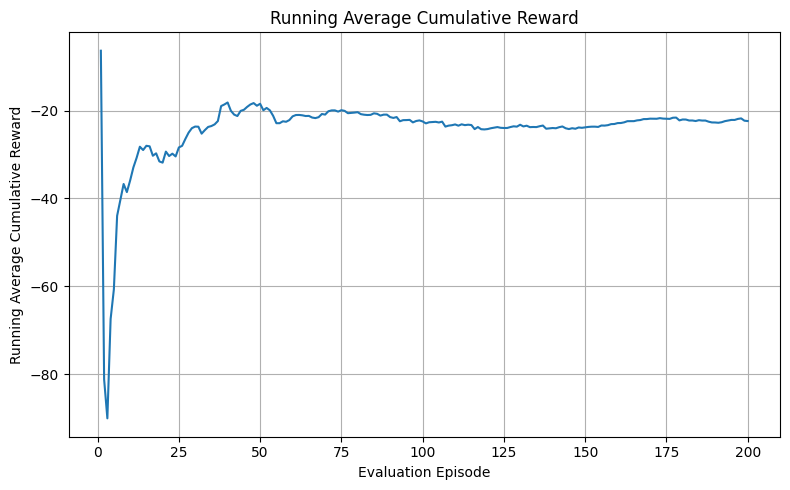

In [12]:
def sample_next_state(s, action):

    data = transitions(s, action)

    states = list(data.keys())
    probabilities = np.array(list(data.values()))

    probabilities = probabilities / probabilities.sum()

    choice = np.random.choice(
        len(states),
        p=probabilities
    )

    return states[choice]


np.random.seed(42)

episode_returns = []

for episode in range(EPISODES):

    s = INITIAL_STATE
    G = 0

    for t in range(MAX_STEPS):

        if s == TERMINAL_STATE:
            break
        action = max(Q[s], key=Q[s].get)

        ns = sample_next_state(s, action)

        r = reward(s, action, ns)

        G += (GAMMA ** t) * r

        s = ns

    episode_returns.append(G)


average_reward = np.mean(episode_returns)
running_average = (
    np.cumsum(episode_returns)
    / np.arange(1, EPISODES + 1)
)

print("\nPERFORMANCE EVALUATION")
print("Episodes:", EPISODES)
print(
    "Average discounted cumulative reward:",
    round(average_reward, 4)
)


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPISODES + 1),
    running_average
)

plt.xlabel("Evaluation Episode")
plt.ylabel("Running Average Cumulative Reward")
plt.title("Running Average Cumulative Reward")
plt.grid()
plt.tight_layout()
plt.show()

RUNNING AVERAGE CUMULATIVE REWARD

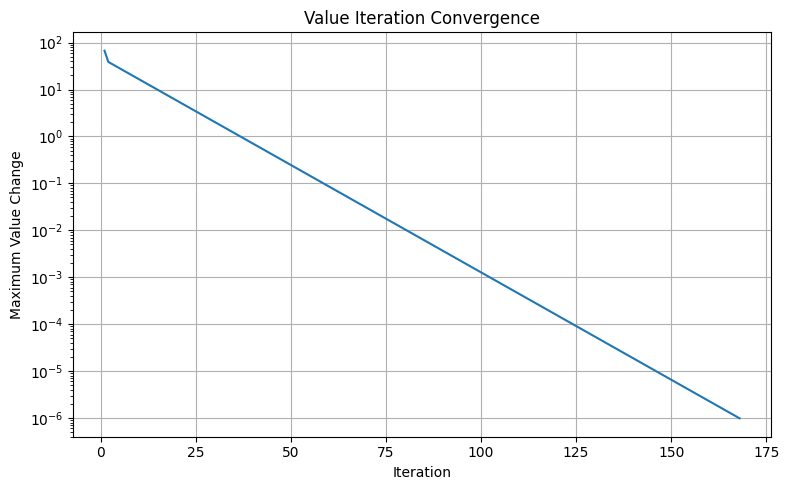

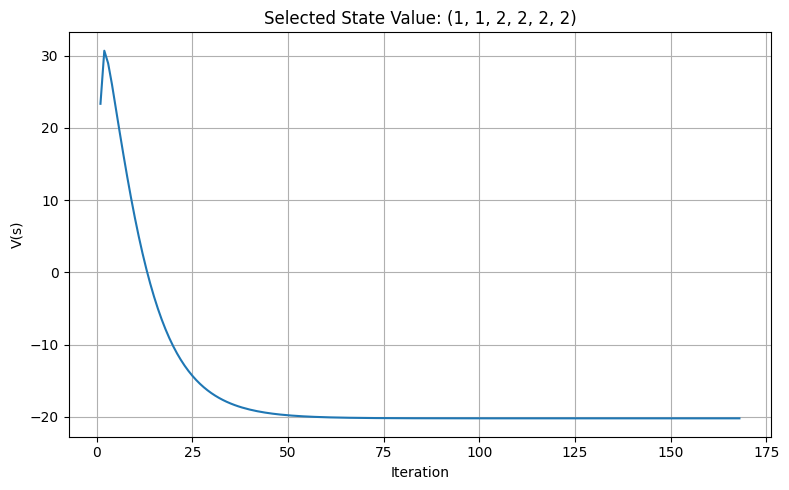

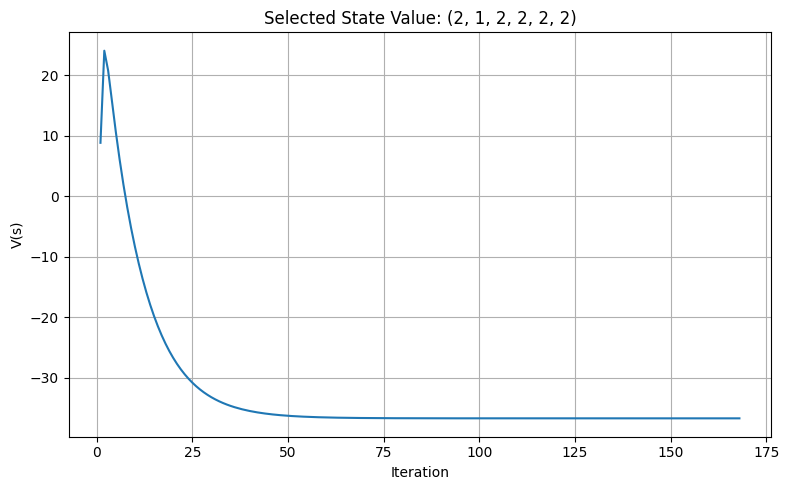

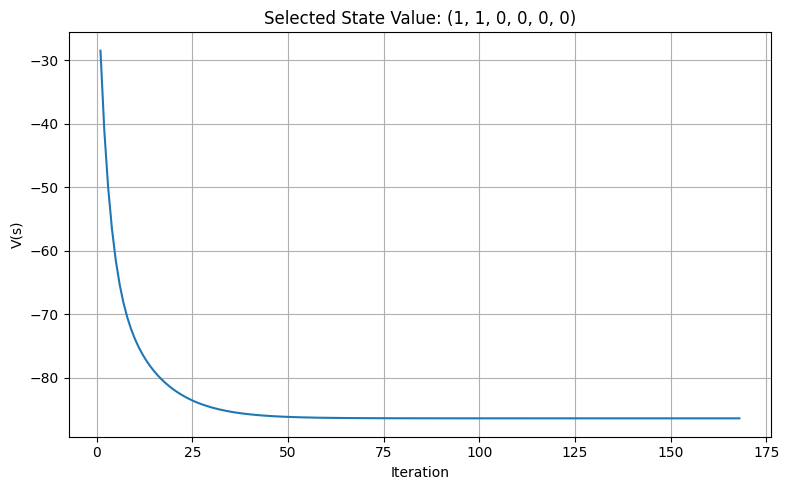

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(delta_history) + 1),
    delta_history
)

plt.xlabel("Iteration")
plt.ylabel("Maximum Value Change")
plt.title("Value Iteration Convergence")
plt.yscale("log")
plt.grid()
plt.tight_layout()
plt.show()

for s in selected_states:

    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(selected_history[s]) + 1),
        selected_history[s]
    )

    plt.xlabel("Iteration")
    plt.ylabel("V(s)")
    plt.title("Selected State Value: " + str(s))
    plt.grid()
    plt.tight_layout()
    plt.show()
